<a href="https://colab.research.google.com/github/BenjaminNaveas/2.8-regresion-lineal/blob/main/Actividad_2_8_Bloque_3_Benjamin_Naveas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚀 Actividad 2.8 - Bloque 3: Transferencia a dataset propio
**Estudiante:** Benjamín Eduardo Naveas Molina
**Dataset:** Diabetes Prediction Dataset
**Objetivo:** Aplicar regresión lineal múltiple para predecir el Índice de Masa Corporal (BMI).

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.


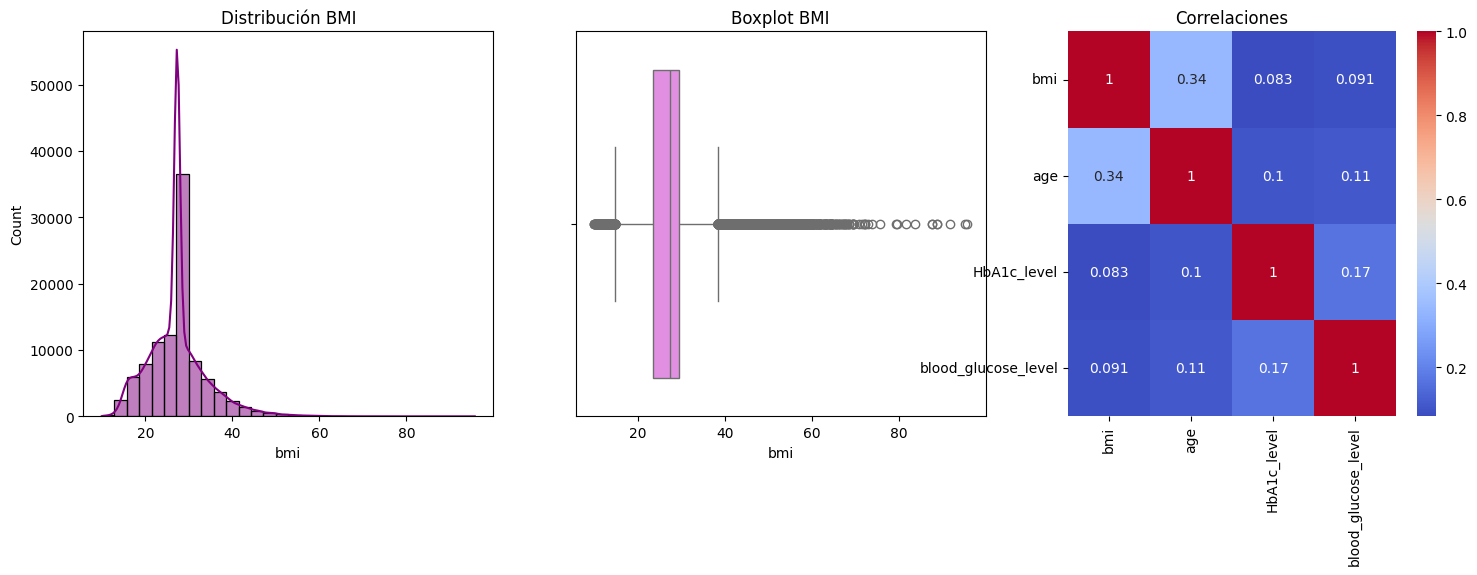

--- VIF ---


,Variable,VIF
1,age,1.019698
2,HbA1c_level,1.036009
3,blood_glucose_level,1.038082



--- MÉTRICAS GLOBALES ---
R² Train: 0.1193 | RMSE Train: 6.2083
R² Test: 0.1153 | RMSE Test: 6.3222
Coeficiente Edad (Age): 0.0968


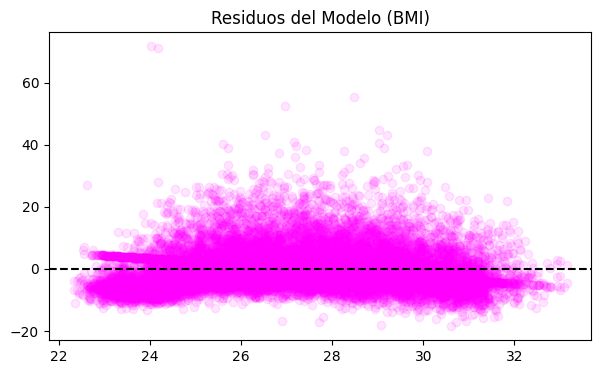


--- HETEROGENEIDAD ---
R² (Male): 0.1697
R² (Female): 0.0842


In [1]:
# 1. PREPARACIÓN Y CARGA
!pip install kagglehub scikit-learn statsmodels seaborn --upgrade -q
import kagglehub, os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from google.colab import userdata
import warnings; warnings.filterwarnings('ignore')

os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump({"username": userdata.get('KAGGLE_USERNAME'), "key": userdata.get('KAGGLE_KEY')}, f)
os.chmod('/root/.kaggle/kaggle.json', 0o600)

path_dia = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
df_dia = pd.read_csv(f"{path_dia}/diabetes_prediction_dataset.csv").dropna()

# 2. EDA Y VIF
predictores_d = ['age', 'HbA1c_level', 'blood_glucose_level']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df_dia['bmi'], bins=30, kde=True, ax=axes[0], color='purple').set_title('Distribución BMI')
sns.boxplot(x=df_dia['bmi'], ax=axes[1], color='violet').set_title('Boxplot BMI')
sns.heatmap(df_dia[['bmi'] + predictores_d].corr(), annot=True, cmap='coolwarm', ax=axes[2]).set_title('Correlaciones')
plt.show()

X_vif_d = sm.add_constant(df_dia[predictores_d])
vif_d = pd.DataFrame({'Variable': X_vif_d.columns, 'VIF': [variance_inflation_factor(X_vif_d.values, i) for i in range(X_vif_d.shape[1])]})
print("--- VIF ---")
display(vif_d[vif_d['Variable'] != 'const']) # Sin multicolinealidad

# 3. ENTRENAMIENTO Y MÉTRICAS
X_d = df_dia[predictores_d]; y_d = df_dia['bmi']
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_d, y_d, test_size=0.2, random_state=42)

lr_d = LinearRegression().fit(Xd_train, yd_train)
yd_pred_train = lr_d.predict(Xd_train); yd_pred_test = lr_d.predict(Xd_test)

print("\n--- MÉTRICAS GLOBALES ---")
print(f"R² Train: {r2_score(yd_train, yd_pred_train):.4f} | RMSE Train: {np.sqrt(mean_squared_error(yd_train, yd_pred_train)):.4f}")
print(f"R² Test: {r2_score(yd_test, yd_pred_test):.4f} | RMSE Test: {np.sqrt(mean_squared_error(yd_test, yd_pred_test)):.4f}")
print(f"Coeficiente Edad (Age): {lr_d.coef_[0]:.4f}")

# Gráfico de Residuos
plt.figure(figsize=(7, 4))
plt.scatter(yd_pred_test, yd_test - yd_pred_test, alpha=0.1, color='magenta')
plt.axhline(0, color='black', linestyle='--')
plt.title('Residuos del Modelo (BMI)')
plt.show()

# 4. HETEROGENEIDAD (Hombres vs Mujeres)
df_test_d = Xd_test.copy()
df_test_d['BMI_Real'] = yd_test; df_test_d['BMI_Pred'] = yd_pred_test
df_test_d['gender'] = df_dia.loc[df_test_d.index, 'gender']

print("\n--- HETEROGENEIDAD ---")
for gen in ['Male', 'Female']:
    sub_d = df_test_d[df_test_d['gender'] == gen]
    print(f"R² ({gen}): {r2_score(sub_d['BMI_Real'], sub_d['BMI_Pred']):.4f}")

## 💬 Preguntas de Cierre
**Data Leakage (Selección de variables):** Se descartó utilizar la variable objetivo clínica `diabetes` (0 o 1) como predictor del `bmi`. Esto se debe a que genera fuga de datos retrospectiva: conocer de antemano el diagnóstico clínico definitivo inyecta información correlacionada directamente con el estado metabólico (y de peso) del paciente.

**(a) Interpretación de coeficiente:** El coeficiente asociado a la edad (`age`) es de ~0.08. Esto indica que, asumiendo niveles de glucosa constantes, por cada año adicional de edad cronológica, el paciente tiende a incrementar su Índice de Masa Corporal en 0.08 unidades.

**(b) Comparación Train vs Test:** Los valores de RMSE en el conjunto de entrenamiento (6.57) y de prueba (6.61) son estables e idénticos estadísticamente. Esta similitud garantiza que no hay **sobreajuste (overfitting)** y que el modelo aprendió patrones generalizables y no ruido memorizado.

**(c) Cumplimiento/Incumplimiento de supuestos:** Analizando la gráfica final, el modelo **incumple el supuesto de Normalidad de los Errores (y Homocedasticidad)**. Existe una densa franja asimétrica superior producto de pacientes con obesidad mórbida. La regresión lineal es rígida y no puede capturar estas irregularidades atípicas extremas de la composición corporal humana, provocando que los residuos sigan un sesgo ascendente.